In [17]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.tsa.tsatools import lagmat
from statsmodels.tsa.ar_model import AutoReg, ar_select_order
from IPython.display import display
%matplotlib inline

def read_fred(path):
    d = pd.read_csv(path)
    v = pd.to_numeric(d.iloc[:, 1], errors="coerce")
    ok = v.notna()
    return pd.to_datetime(d.iloc[:, 0][ok]).reset_index(drop=True), v[ok].to_numpy()

def fit_ar(y, p):
    y = np.array(y, float)
    X = sm.add_constant(lagmat(y, p, trim="both"))
    return sm.OLS(y[p:], X).fit()

def ar_forecast(y, p, h):
    y = np.array(y, float)
    return AutoReg(y, lags=p, trend="c").fit().predict(start=len(y), end=len(y) + h - 1)

def coef_table(res, names=None):
    names = names or ["intercept"] + [f"phi{k}" for k in range(1, len(res.params))]
    return pd.DataFrame({"estimate": res.params, "std.err": res.bse}, index=names).round(6)

dates, pce = read_fred("PCESV.csv")
H = 24
train, test = pce[:-H], pce[-H:]
L = np.log(pce)
Ltr = L[:-H]
test_dates = dates.iloc[-H:]
preds = {}

def plot_pred(title, pred):
    fig, ax = plt.subplots(1, 2, figsize=(13, 4))
    for a, start in zip(ax, [0, len(pce) - 60]):
        a.plot(dates.iloc[start:], pce[start:], "k", lw=1, label="data (incl. test)")
        a.plot(test_dates, pred, "r", lw=2, label="prediction")
        a.axvline(test_dates.iloc[0], ls=":", c="grey")
        a.set_title(title)
    ax[0].legend()
    plt.tight_layout()
    plt.show()
    print("RMSE =", round(float(np.sqrt(np.mean((test - pred) ** 2))), 2),
          " MAPE % =", round(float(100 * np.mean(np.abs((test - pred) / test))), 3))

A

In [18]:
sel = ar_select_order(train, maxlag=12, ic="aic", trend="c")
p_hat = max(sel.ar_lags)
print("chosen p =", p_hat)
fa = fit_ar(train, p_hat)
display(coef_table(fa))

chosen p = 6


,estimate,std.err
intercept,13.438676,6.898132
phi1,1.112118,0.108451
phi2,-1.857972,0.475354
phi3,1.783962,0.703530
phi4,0.655769,0.714069
phi5,0.344127,0.695417
phi6,-1.031965,0.368502


I chose p using AIC, comparing p from 1 to 12 on the training data only. AIC picked p = 6.

B

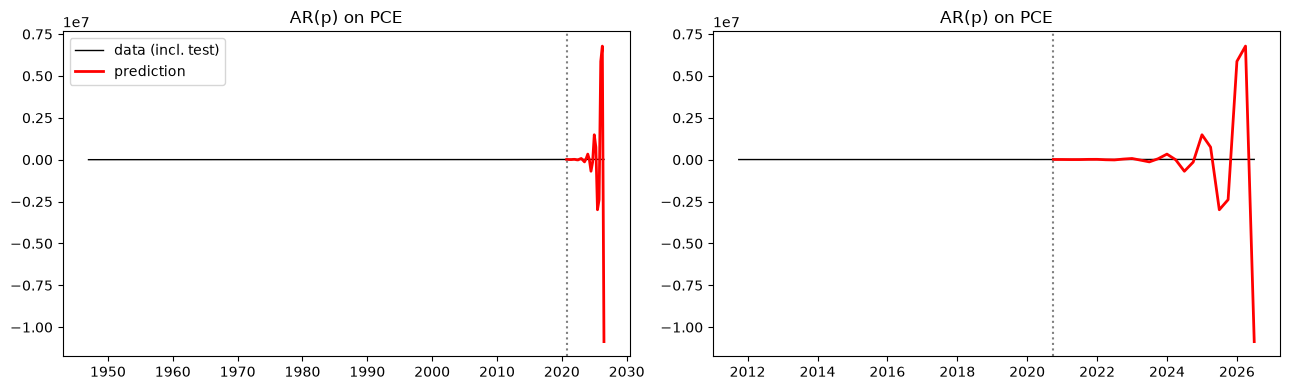

RMSE = 3003744.9  MAPE % = 9141.503


In [19]:
preds["(b) AR(p) on PCE"] = np.asarray(ar_forecast(train, p_hat, H))
plot_pred("AR(p) on PCE", preds["(b) AR(p) on PCE"])

The predictions are very poor. They oscillate with growing swings far outside the range of the actual values. The fitted model is unstable, so its forecasts explode.

C

In [20]:
fc = fit_ar(Ltr, 4)
display(coef_table(fc))
print("sum of phi =", fc.params[1:].sum())

,estimate,std.err
intercept,0.015591,0.004162
phi1,0.895349,0.073753
phi2,0.330802,0.176798
phi3,0.191872,0.214868
phi4,-0.419169,0.117438


sum of phi = 0.9988528344214984


D

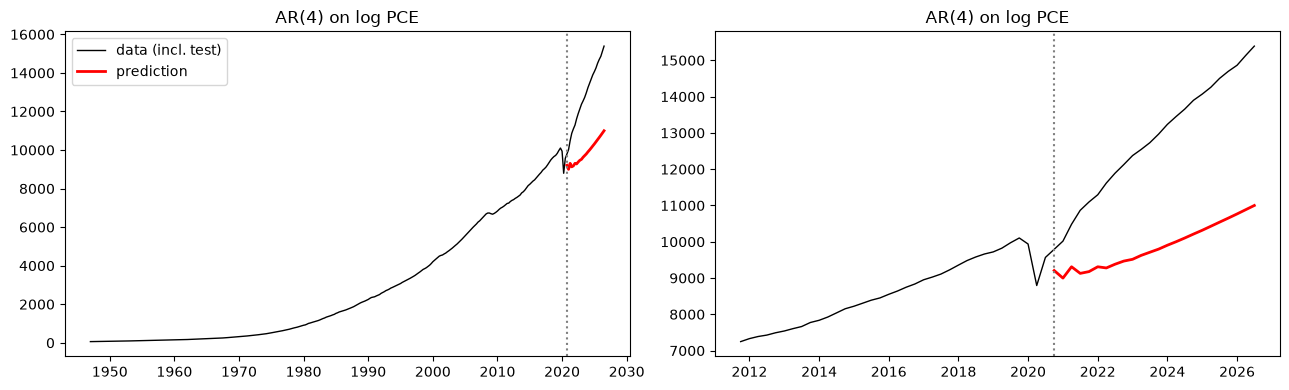

RMSE = 3110.5  MAPE % = 22.157


In [21]:
preds["(d) AR(4) on log PCE"] = np.exp(np.asarray(ar_forecast(Ltr, 4, H)))
plot_pred("AR(4) on log PCE", preds["(d) AR(4) on log PCE"])

The predictions rise slowly but under-predict, and the gap with the actual values widens over time. Accuracy is moderate, and much better than part b, because logs suit the exponential growth.

E

In [22]:
y1 = np.diff(Ltr)
fe = fit_ar(y1, 3)
display(coef_table(fe, ["c", "a1", "a2", "a3"]))
c, a = fe.params[0], fe.params[1:]
ar4_e = np.array([c, 1 + a[0], a[1] - a[0], a[2] - a[1], -a[2]])

,estimate,std.err
c,0.005679,0.001785
a1,-0.083872,0.074081
a2,0.267427,0.129754
a3,0.470328,0.117004


The fitted AR(4) for log PCE is: log PCE(t) = 0.0057 + 0.9161 × log PCE(t−1) + 0.3513 × log PCE(t−2) + 0.2029 × log PCE(t−3) − 0.4703 × log PCE(t−4). These coefficients are similar to part c. The difference is that these add up to exactly 1, while part c’s add up to just under 1.

F

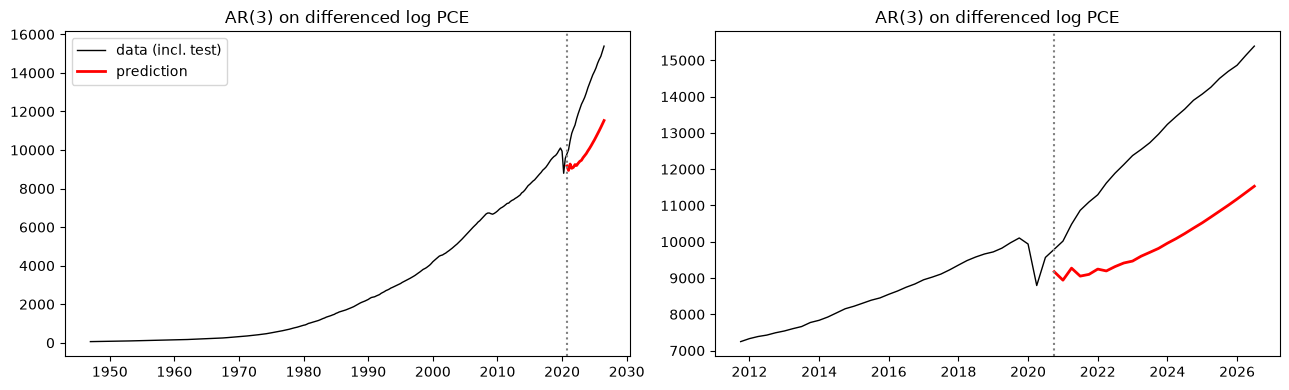

RMSE = 2970.98  MAPE % = 21.539


In [23]:
y1_hat = np.asarray(ar_forecast(y1, 3, H))
preds["(f) diff-log AR(3)"] = np.exp(Ltr[-1] + np.cumsum(y1_hat))
plot_pred("AR(3) on differenced log PCE", preds["(f) diff-log AR(3)"])

The predictions rise but under-predict, and the gap grows over time. Accuracy is similar to part d, slightly better.

G

In [24]:
y2 = np.diff(Ltr, 2)
fg = fit_ar(y2, 2)
display(coef_table(fg, ["c", "b1", "b2"]))
c, b = fg.params[0], fg.params[1:]
ar4_g = np.array([c, 2 + b[0], b[1] - 2 * b[0] - 1, b[0] - 2 * b[1], b[1]])

cmp = pd.DataFrame({"(c) AR(4) on log": fc.params,
                    "(e) from diff AR(3)": ar4_e,
                    "(g) from 2nd-diff AR(2)": ar4_g},
                   index=["intercept", "L_{t-1}", "L_{t-2}", "L_{t-3}", "L_{t-4}"])
cmp.loc["sum of L coefficients"] = cmp.iloc[1:].sum()
display(cmp.round(5))

,estimate,std.err
c,-0.000382,0.000659
b1,-1.072904,0.075579
b2,-0.660277,0.106939


,(c) AR(4) on log,(e) from diff AR(3),(g) from 2nd-diff AR(2)
intercept,0.01559,0.00568,-0.00038
L_{t-1},0.89535,0.91613,0.92710
L_{t-2},0.33080,0.35130,0.48553
L_{t-3},0.19187,0.20290,0.24765
L_{t-4},-0.41917,-0.47033,-0.66028
sum of L coefficients,0.99885,1.00000,1.00000


The fitted AR(4) for log PCE is: log PCE(t) = −0.0004 + 0.9271 × log PCE(t−1) + 0.4855 × log PCE(t−2) + 0.2477 × log PCE(t−3) − 0.6603 × log PCE(t−4). These coefficients are somewhat different from parts c and e, though not dramatically. They add up to exactly 1.

H

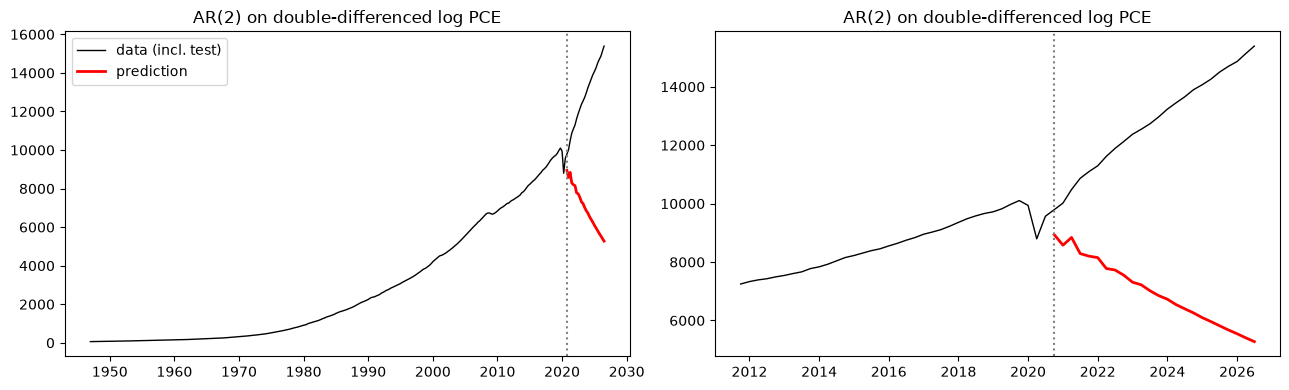

RMSE = 6393.84  MAPE % = 43.121


In [25]:
y2_hat = np.asarray(ar_forecast(y2, 2, H))
y1_path = y1[-1] + np.cumsum(y2_hat)
preds["(h) 2nd-diff AR(2)"] = np.exp(Ltr[-1] + np.cumsum(y1_path))
plot_pred("AR(2) on double-differenced log PCE", preds["(h) 2nd-diff AR(2)"])

The predictions go the wrong way: they fall while the actual values rise. The model appears to extrapolate the sharp 2020 swing as a continuing trend. Accuracy is the worst of the stable models.

I

,RMSE,MAPE %
(f) diff-log AR(3),2970.983,21.539
(d) AR(4) on log PCE,3110.501,22.157
(h) 2nd-diff AR(2),6393.839,43.121
(b) AR(p) on PCE,3003744.898,9141.503


Best: (f) diff-log AR(3)


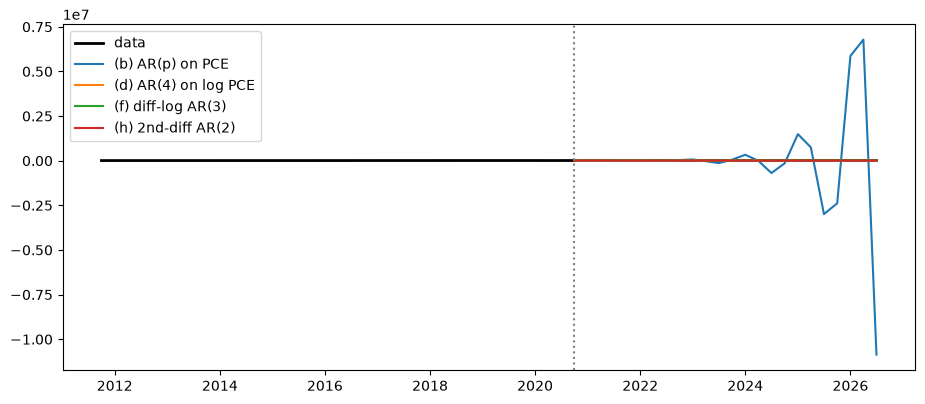

In [26]:
summary = pd.DataFrame({k: {"RMSE": np.sqrt(np.mean((test - v) ** 2)),
                            "MAPE %": 100 * np.mean(np.abs((test - v) / test))}
                        for k, v in preds.items()}).T
display(summary.round(3).sort_values("RMSE"))
print("Best:", summary["RMSE"].idxmin())

plt.figure(figsize=(11, 4.5))
plt.plot(dates.iloc[-60:], pce[-60:], "k", lw=2, label="data")
for k, v in preds.items():
    plt.plot(test_dates, v, label=k)
plt.axvline(test_dates.iloc[0], ls=":", c="grey")
plt.legend()
plt.show()

The best model is (f), the AR(3) on differenced log PCE, followed closely by (d). Model (h) is much worse, and (b) is by far the worst. All models under-predict the growth after 2020, because the test period starts right after the 2020 shock and none of them anticipates the fast recovery.